# heatwaves_Hobday2016_obs.ipynb
## Calculate marine heatwaves with Observations using the method outlined in Hobday et al. 2016

#### Created by Brendan Myers
##### 09/02/2026

In [1]:
%matplotlib inline
# import warnings
# warnings.filterwarnings('ignore')
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs

import pandas as pd

from statistics import mean
from matplotlib import style
import colorcet as cc
from scipy import stats

import xesmf #for regridding
xr.set_options(keep_attrs=True)
import regionmask #for generating 1° ocean mask
# import m6toolbox

import xmhw

ERROR 1: PROJ: proj_create_from_database: Open of /glade/work/brendanmy/conda-envs/bgc-env/share/proj failed


### Make a standard 1° ones masks for masking, etc. (one for lons -180 to 180 and one for lons 0 to 360)

In [2]:
ones2 = np.full((180,360),1,dtype=int)
ones2 = xr.DataArray(ones2,dims=('lat','lon'))
ones2['lat'] = np.arange(-89.5, 90, 1)
ones2['lon'] = np.arange(0.5, 360, 1)

### Read in the standard 1° basin mask

In [3]:
# Define the 1-degree latitude and longitude points
lon = np.arange(-179.5, 180, 1)
lat = np.arange(-89.5, 90, 1)

# Create the land mask using Natural Earth data (default resolution is 1:110m)
# The mask will be boolean (True for land) on the specified grid
land_mask = regionmask.defined_regions.natural_earth_v5_1_2.land_110.mask(lon, lat)
land_mask = land_mask.where(land_mask==0, other=1)

In [4]:
ones = np.full((180,360),1,dtype=int)
ones = xr.DataArray(ones,dims=('lat','lon'))
ones['lat'] = np.arange(-89.5, 90, 1)
ones['lon'] = np.arange(-179.5, 180, 1)
ones = ones.where(land_mask == 1)

In [5]:
### forth, get the major basins mask, created using 'make_major_basins_mask.ipynb'
major_basins = xr.open_dataset('../tools/major_basins_1x1.nc')

major_basins = major_basins.basin.values
major_basins = xr.DataArray(major_basins, dims=('lat','lon'))

# Read in observational data monthly climatologies that have been regridded to 1°

In [ ]:
file = '../tools/Obs4biomes.nc'
ds_obs_clim = xr.open_dataset(file)

# path = '/glade/campaign/collections/gdex/data/d277000/oiv2mnnc/'
# # files = ['icec.mnmean.nc',  'sst.mnmean.nc']
# files = 'sst.mnmean.nc'
# # ds_obs = xr.open_mfdataset([path+f for f in files]).rename({'sst':'SST', 'icec':'Ice'})

# ds_obs = xr.open_dataset(path+files).rename({'sst':'SST'})

In [7]:
ds_obs_clim

<xarray.Dataset> Size: 25MB
Dimensions:  (lat: 180, lon: 360, month: 12)
Coordinates:
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * month    (month) float64 96B 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
Data variables:
    MLD      (lat, lon, month) float64 6MB ...
    Chl      (lat, lon, month) float64 6MB ...
    Ice      (lat, lon, month) float64 6MB ...
    SST      (lat, lon, month) float64 6MB ...

In [38]:
ds_obs

<xarray.Dataset> Size: 128MB
Dimensions:    (time: 494, lat: 180, lon: 360, nbnds: 2)
Coordinates:
  * time       (time) datetime64[ns] 4kB 1981-12-01 1982-01-01 ... 2023-01-01
  * lat        (lat) float32 720B 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
  * lon        (lon) float32 1kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
Dimensions without coordinates: nbnds
Data variables:
    SST        (time, lat, lon) float32 128MB ...
    time_bnds  (time, nbnds) datetime64[ns] 8kB ...
Attributes:
    title:          NOAA Optimum Interpolation (OI) SST V2
    Conventions:    CF-1.0
    history:        Wed Apr  6 13:47:45 2005: ncks -d time,0,278 SAVEs/sst.mn...
    comments:       Data described in  Reynolds, R.W., N.A. Rayner, T.M.\nSmi...
    platform:       Model
    source:         NCEP Climate Modeling Branch
    institution:    National Centers for Environmental Prediction
    References:     https://www.psl.noaa.gov/data/gridded/data.noaa.oisst.v2....
    dataset_title:  NOAA Optimum Interpolation (OI) SST V2
    source_url:     http://www.emc.ncep.noaa.gov/research/cmb/sst_analysis/

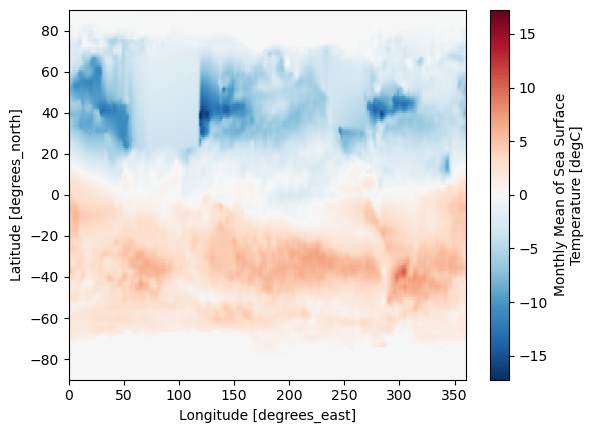

In [42]:
(ds_obs.isel(time=3).SST-ds_obs.isel(time=10).SST).plot()

# A few precalculations....

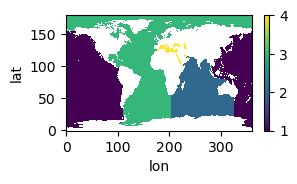

In [9]:
major_basins.plot(figsize=(3,1.5))

### Assign basins

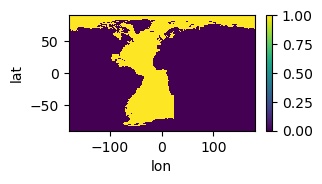

In [10]:
Atlantic = ones.where(major_basins == 3, other=0)
#.where(major_basins.basin == 3) #ones.where(ds_grid.REGION_MASK >= 5, other=0).where(ds_grid.REGION_MASK<10, other=0)
Atlantic.plot(figsize=(3,1.5))

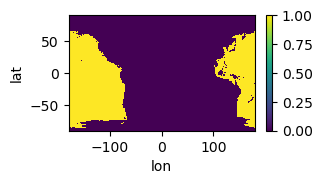

In [11]:
Pacific = ones.where(major_basins == 1, other=0)
Pacific.plot(figsize=(3,1.5))

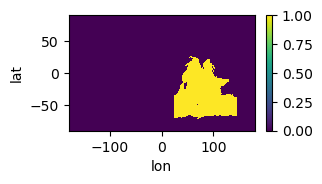

In [12]:
Indian = ones.where(major_basins == 2, other=0)
Indian.plot(figsize=(3,1.5))

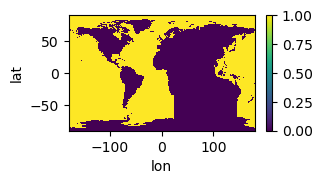

In [13]:
Atlantic_Pacific = Atlantic + Pacific
Atlantic_Pacific.plot(figsize=(3,1.5))

In [14]:
ds_obs['basin_mask'] = major_basins
ds_obs

<xarray.Dataset> Size: 257MB
Dimensions:     (lat: 180, lon: 360, time: 494, nbnds: 2)
Coordinates:
  * lat         (lat) float32 720B 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
  * lon         (lon) float32 1kB 0.5 1.5 2.5 3.5 ... 356.5 357.5 358.5 359.5
  * time        (time) datetime64[ns] 4kB 1981-12-01 1982-01-01 ... 2023-01-01
Dimensions without coordinates: nbnds
Data variables:
    Ice         (time, lat, lon) float32 128MB dask.array<chunksize=(447, 180, 360), meta=np.ndarray>
    time_bnds   (time, nbnds) datetime64[ns] 8kB dask.array<chunksize=(494, 2), meta=np.ndarray>
    SST         (time, lat, lon) float32 128MB dask.array<chunksize=(494, 180, 360), meta=np.ndarray>
    basin_mask  (lat, lon) float64 518kB nan nan nan nan nan ... 3.0 3.0 3.0 3.0
Attributes:
    title:          NOAA Optimum Interpolation (OI) SST V2
    Conventions:    CF-1.0
    history:        Wed Apr  6 13:51:42 2005: ncks -d time,0,278 SAVEs/icec.m...
    comments:       Data described in  Reynolds, R.W., N.A. Rayner, T.M.\nSmi...
    platform:       Model
    source:         NCEP Climate Modeling Branch
    institution:    National Centers for Environmental Prediction
    References:     https://www.esrl.noaa.gov/psd/data/gridded/data.noaa.oiss...
    NCO:            4.0.0
    dataset_title:  NOAA Optimum Interpolation (OI) SST V2
    source_url:     http://www.emc.ncep.noaa.gov/research/cmb/sst_analysis/

In [15]:
# ds_obs.SST.where(~np.isnan(ds_obs.SST), drop=True).values

In [16]:
ds_obs['SST_anom'] = ds_obs['SST'] - ds_obs['SST']
ds_obs['SST_anom'].attrs = ds_obs['SST_anom'].attrs | {'long_name': 'Sea Surface Temperature Anomoly'}

In [17]:
ds_obs.load()

<xarray.Dataset> Size: 385MB
Dimensions:     (lat: 180, lon: 360, time: 494, nbnds: 2)
Coordinates:
  * lat         (lat) float32 720B 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
  * lon         (lon) float32 1kB 0.5 1.5 2.5 3.5 ... 356.5 357.5 358.5 359.5
  * time        (time) datetime64[ns] 4kB 1981-12-01 1982-01-01 ... 2023-01-01
Dimensions without coordinates: nbnds
Data variables:
    Ice         (time, lat, lon) float32 128MB 100.0 100.0 100.0 ... nan nan nan
    time_bnds   (time, nbnds) datetime64[ns] 8kB 1981-12-01 ... 2023-02-01
    SST         (time, lat, lon) float32 128MB -1.79 -1.79 -1.79 ... -1.79 -1.79
    basin_mask  (lat, lon) float64 518kB nan nan nan nan nan ... 3.0 3.0 3.0 3.0
    SST_anom    (time, lat, lon) float32 128MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
Attributes:
    title:          NOAA Optimum Interpolation (OI) SST V2
    Conventions:    CF-1.0
    history:        Wed Apr  6 13:51:42 2005: ncks -d time,0,278 SAVEs/icec.m...
    comments:       Data described in  Reynolds, R.W., N.A. Rayner, T.M.\nSmi...
    platform:       Model
    source:         NCEP Climate Modeling Branch
    institution:    National Centers for Environmental Prediction
    References:     https://www.esrl.noaa.gov/psd/data/gridded/data.noaa.oiss...
    NCO:            4.0.0
    dataset_title:  NOAA Optimum Interpolation (OI) SST V2
    source_url:     http://www.emc.ncep.noaa.gov/research/cmb/sst_analysis/

# Calc Heatwaves

In [18]:
import pandas as pd
from matplotlib.colors import BoundaryNorm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap

def blue2red_cmap(n):
    """ combine two existing color maps to create a diverging color map with white in the middle
    n = the number of contour intervals
    """
    if (int(n/2) == n/2):
        # even number of contours
        nwhite=1
        nhalf=n//2
    else:
        nwhite=2
        nhalf = (n-1)//2

    #making mpl colormap from ncl colortable
    cmap_name='nrl_sirkes'
    colortab=pd.read_csv('https://www.ncl.ucar.edu/Document/Graphics/ColorTables/Files/'+cmap_name+'.rgb',sep='\\s+')
    cmap = LinearSegmentedColormap.from_list(cmap_name, colortab.values/255, N=(nhalf*2))

    colorsall = cmap(np.linspace(0,1, nhalf*2))
    
    colors1 = colorsall[:nhalf]
    colors2 = colorsall[nhalf:]
    colorsw = np.ones((nwhite,4))
    colors = np.vstack((colors1, colorsw, colors2))
    cmap = mcolors.LinearSegmentedColormap.from_list('my_colormap', colors)
    return cmap

In [19]:
# cmap_div = cc.cm.coolwarm
levs = np.arange(-4, 4.05, .05)
cmap_div = blue2red_cmap(len(levs))
cmap_div.set_over("grey")  # Color for data above vmax
cmap_div.set_under("grey")


norm = BoundaryNorm(levs, ncolors=cmap_div.N, clip=False)

## Monthly

In [20]:
ds_obs['SST_anom_mon'] = ds_obs['SST'].groupby('time.month') - ds_obs['SST'].groupby('time.month').mean(dim='time')
ds_obs['SST_anom_mon'].attrs = ds_obs['SST_anom_mon'].attrs | {'long_name': 'SST Anomoly'}

In [21]:
# Need groupby to do this by month
quantile_upp_mon = ds_obs.SST_anom_mon.groupby('time.month').quantile(0.9, dim='time', skipna=True)
quantile_low_mon = ds_obs.SST_anom_mon.groupby('time.month').quantile(0.1, dim='time', skipna=True)


tmp_g = ds_obs.groupby('time.month')

mon_sep_list_mhw = []
mon_sep_list_mcw = []
for i, mon in enumerate(range(1,13)):
    tmp = tmp_g[mon]
    mon_sep_list_mhw.append(tmp.SST_anom_mon.where((tmp.SST_anom_mon>=quantile_upp_mon[i]) | (ds_obs.SST_anom_mon.isnull()), other=-9999).drop_vars(['month']))
    mon_sep_list_mcw.append(tmp.SST_anom_mon.where((tmp.SST_anom_mon<=quantile_low_mon[i]) | (ds_obs.SST_anom_mon.isnull()), other=-9999).drop_vars(['month']))

ds_obs['MHW_monthly'] = xr.concat(mon_sep_list_mhw, dim='time', coords='minimal').sortby('time').rename('MHW_monthly')
ds_obs['MHW_monthly'].attrs = ds_obs['MHW_monthly'].attrs | {'quantile': quantile_upp_mon['quantile'].item()}
ds_obs['MCW_monthly'] = xr.concat(mon_sep_list_mcw, dim='time', coords='minimal').sortby('time').rename('MCW_monthly')
ds_obs['MCW_monthly'].attrs = ds_obs['MCW_monthly'].attrs | {'quantile': quantile_low_mon['quantile'].item()}

ds_obs = ds_obs.drop_vars('quantile')

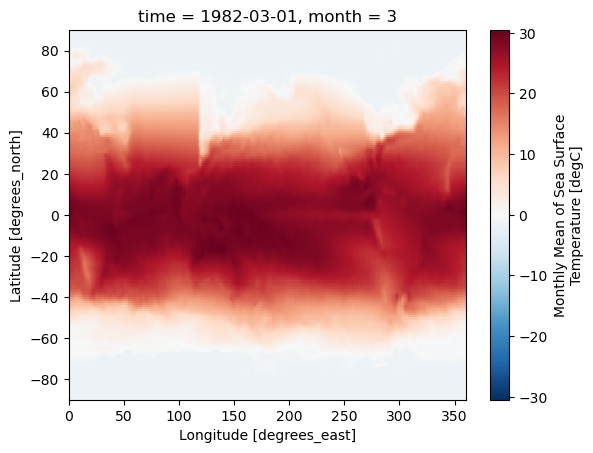

In [26]:
# ds_obs.isel(time=3).SST_anom.plot()

ds_obs.isel(time=3).SST.plot()

KeyboardInterrupt: 

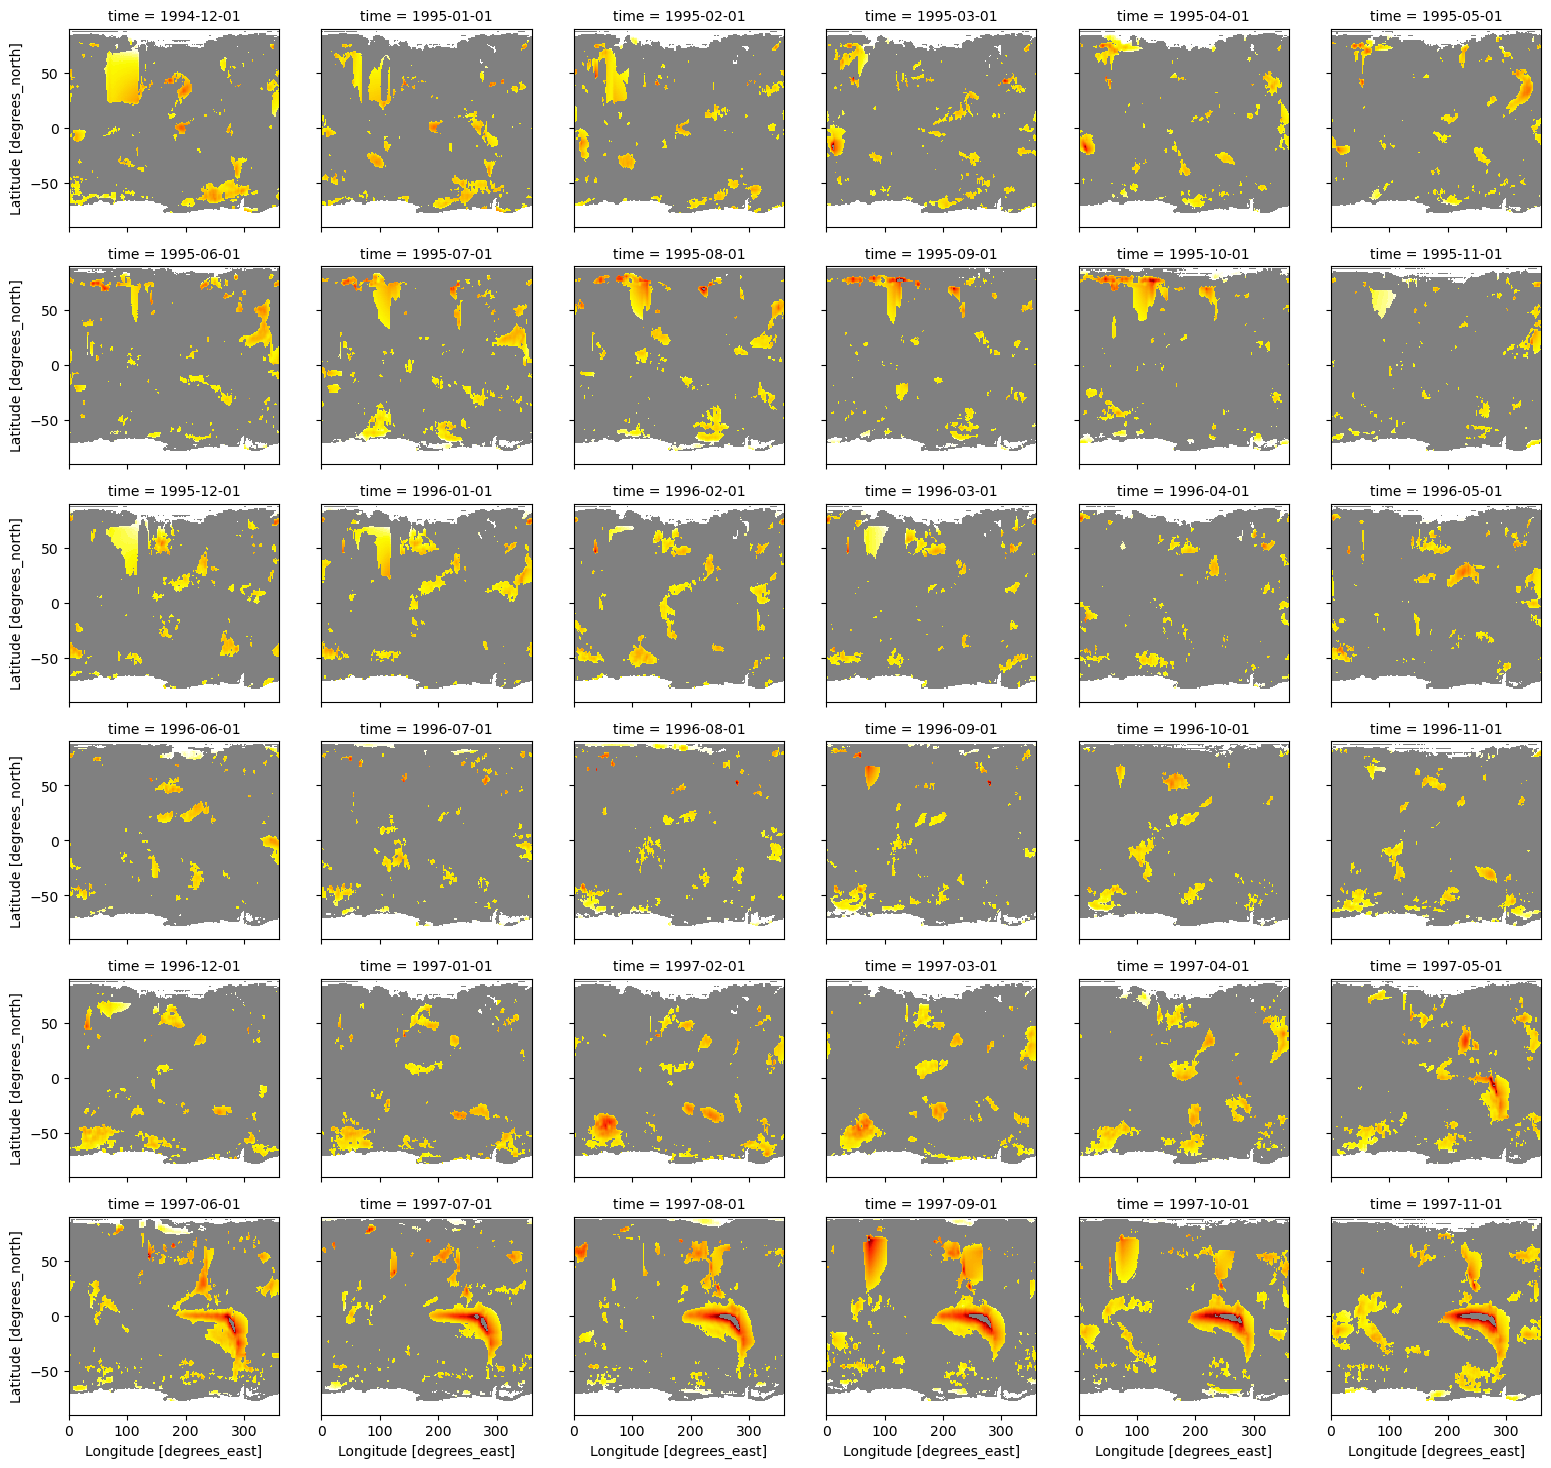

In [22]:
# Marine Heatwaves at Timesteps

ds_obs.isel(time=slice(13*12,16*12)).MHW_monthly.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

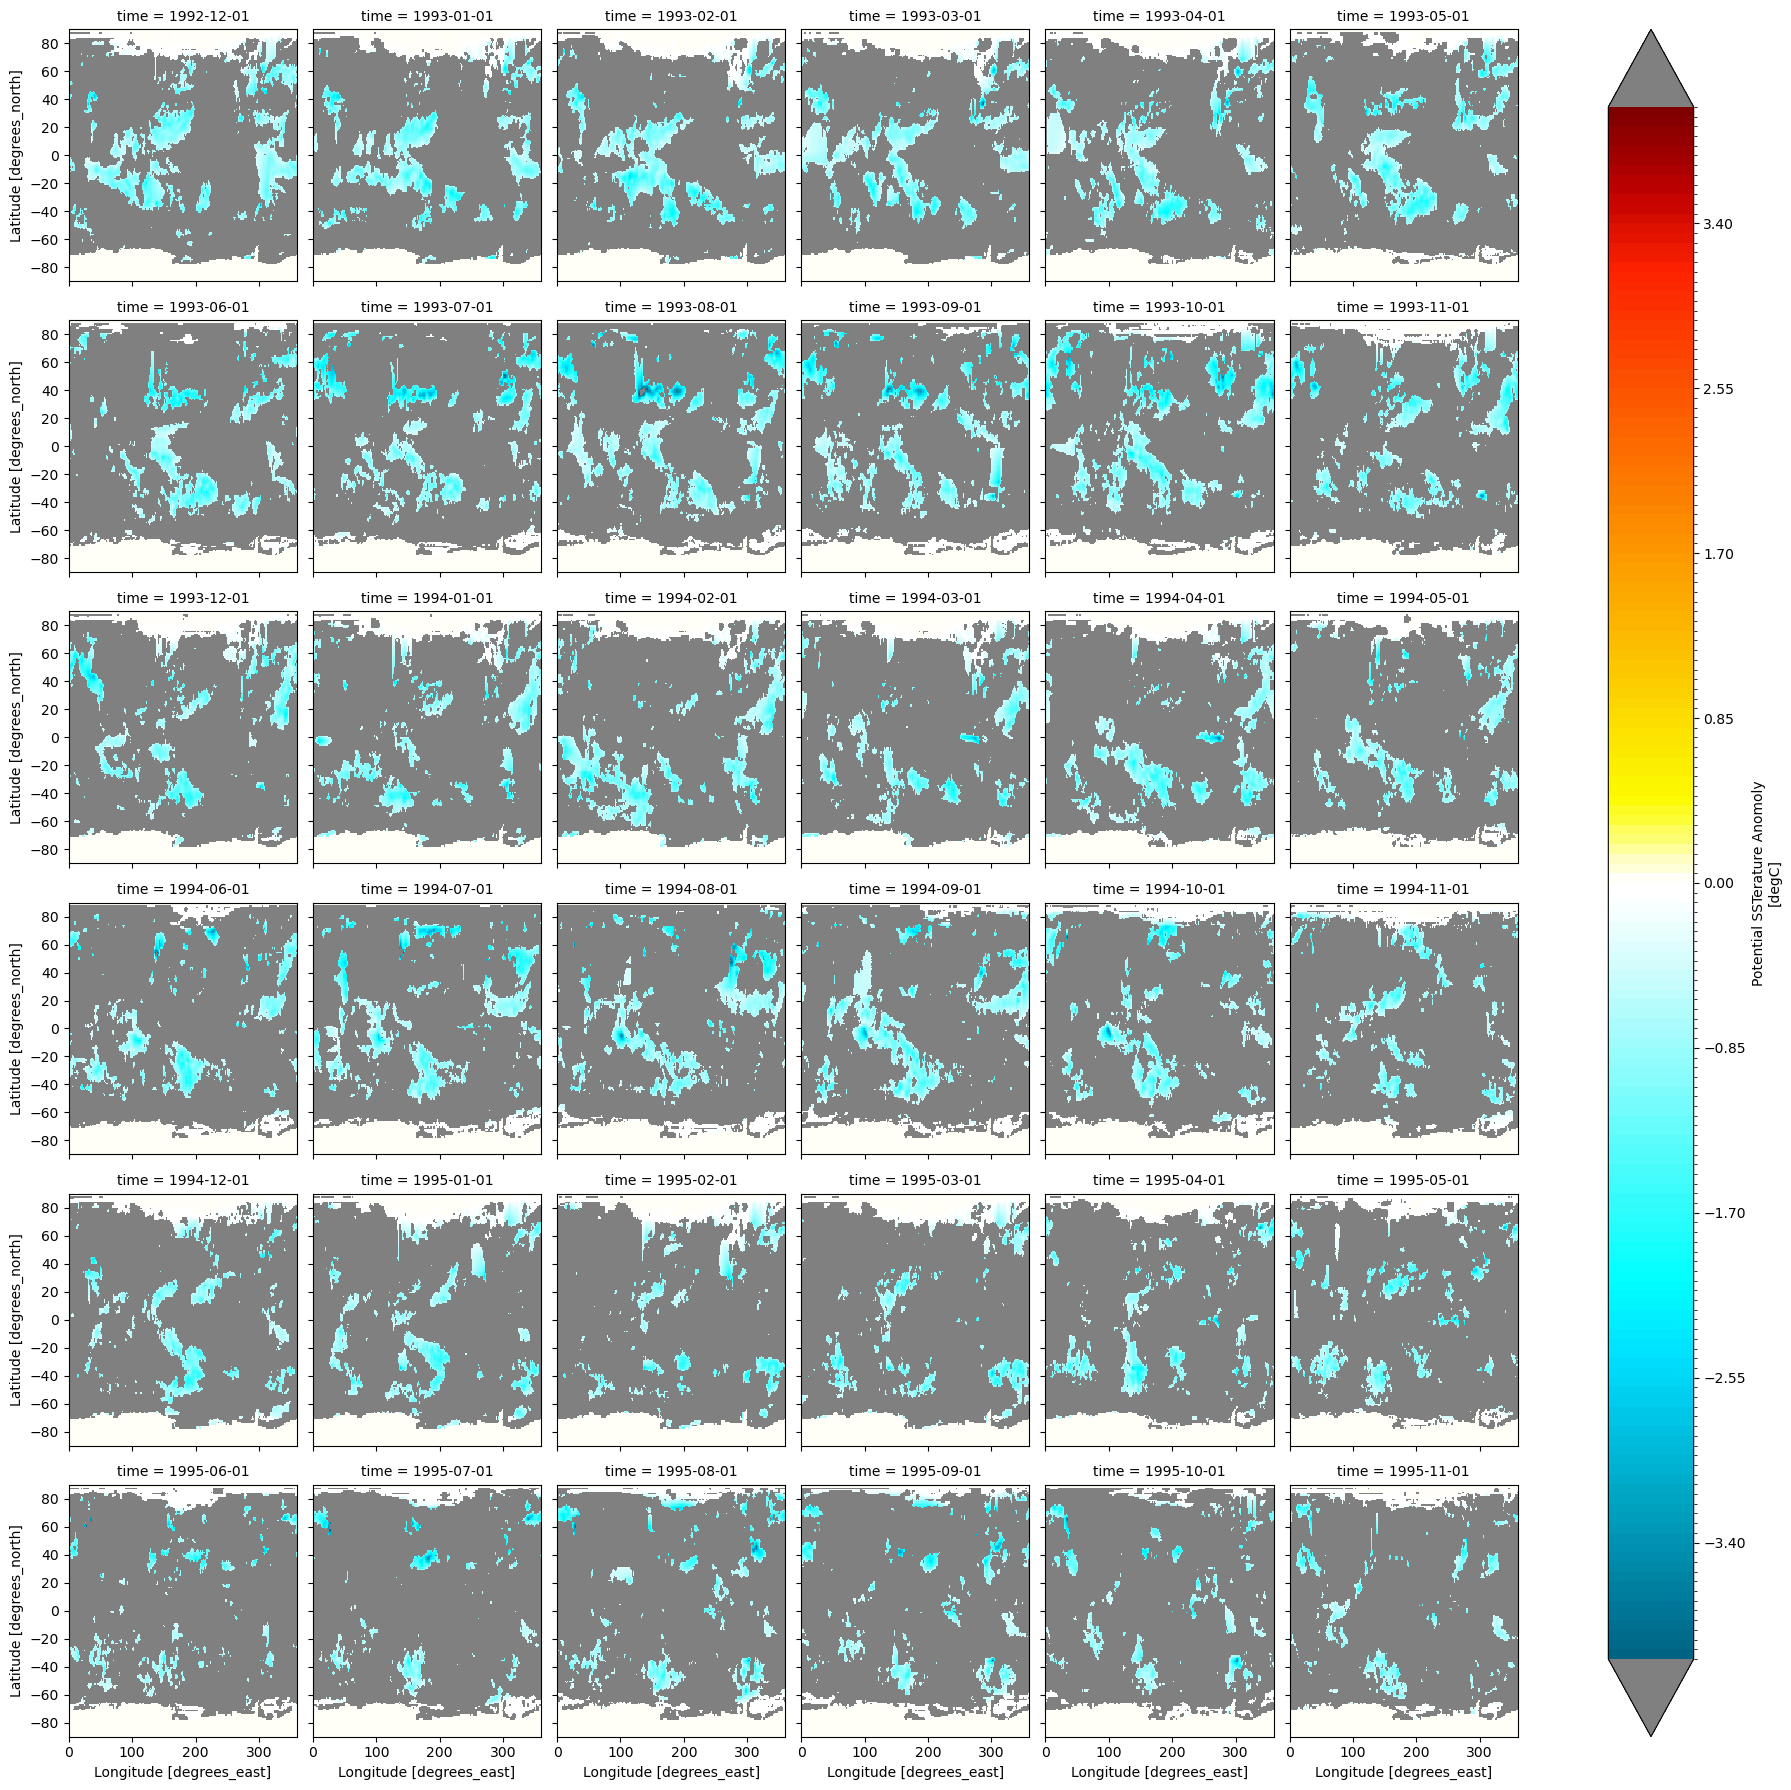

In [ ]:
# Marine Coldwaves at Timesteps

ds_obs.isel(time=slice(11*12,14*12)).MCW_monthly.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

In [ ]:
# Compute Intensity and Merge MHW and MCW together

ds_intensity_mon = xr.merge([ds_obs.MHW_monthly.where(ds_obs.MHW_monthly>-999, drop=False).groupby('time.month').mean('time').rename('MHW_INTENSITY_month'),ds_obs.MCW_monthly.where(ds_obs.MCW_monthly>-999, drop=False).groupby('time.month').mean('time').rename('MCW_INTENSITY_month')])

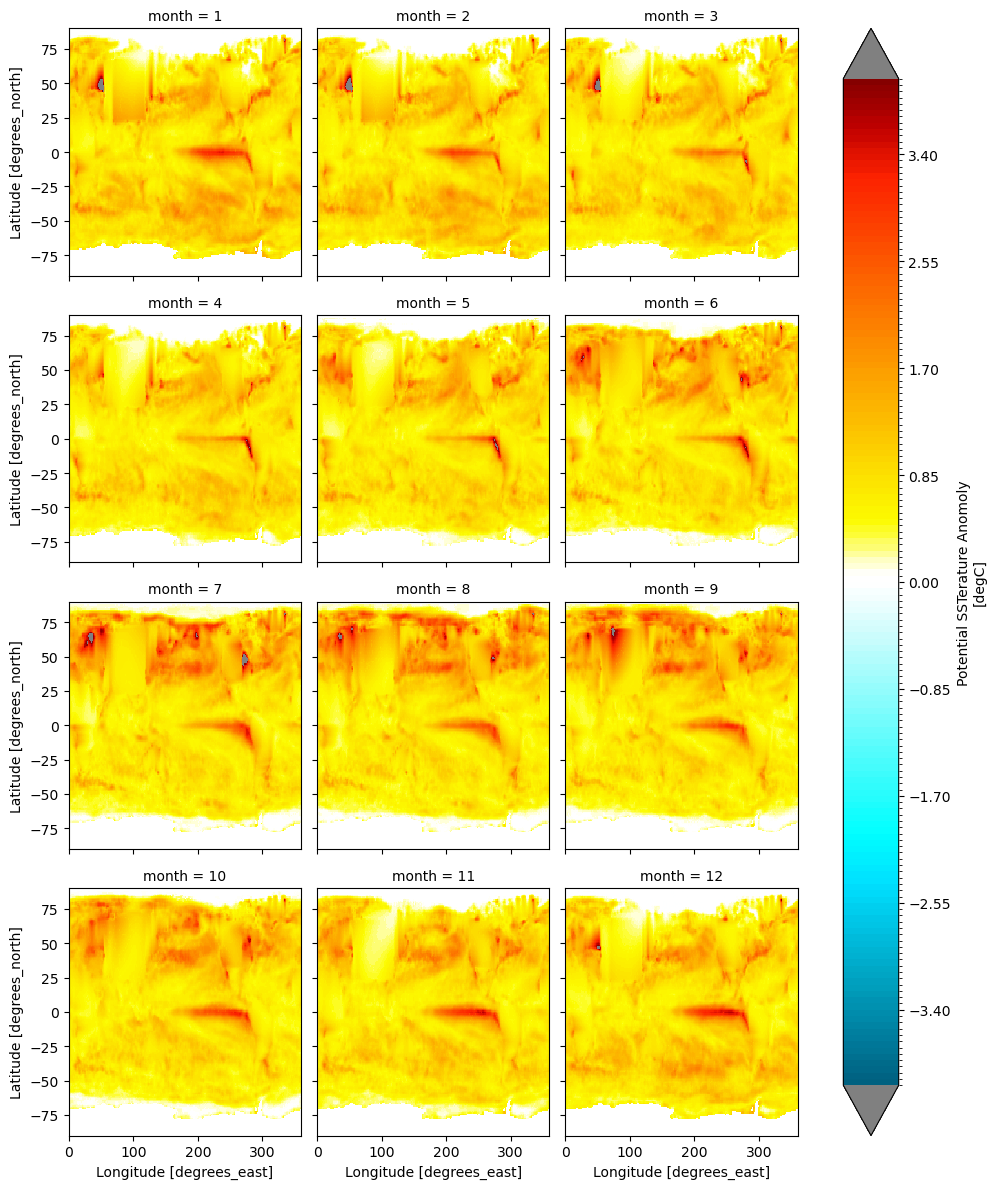

In [ ]:
# Intensity of Marine Heatwaves

ds_intensity_mon['MHW_INTENSITY_month'].plot(col='month',col_wrap=3, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

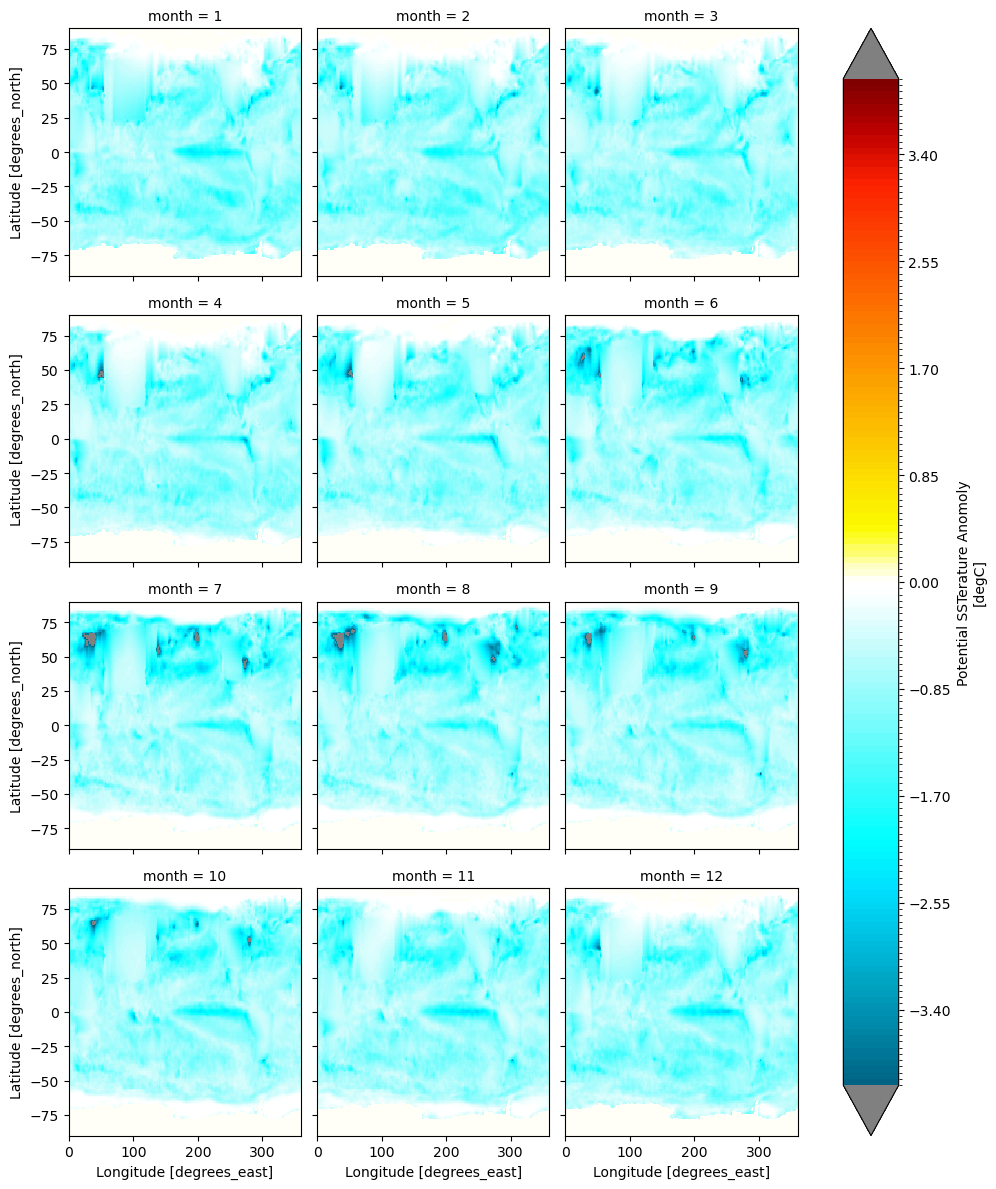

In [ ]:
# Intensity of Marine Coldwaves

ds_intensity_mon['MCW_INTENSITY_month'].plot(col='month',col_wrap=3, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

## Annual

In [ ]:
ds_obs['SST_anom_ann'] = ds_obs['SST'].groupby('time.year') - ds_obs['SST'].groupby('time.year').mean(dim='time')
ds_obs['SST_anom_ann'].attrs = ds_obs['SST_anom_ann'].attrs | {'long_name': 'SST Anomoly'}

In [ ]:
# Need groupby to do this by year
quantile_upp_ann = ds_obs.SST_anom_ann.groupby('time.year').quantile(0.9, dim='time', skipna=True)
quantile_low_ann = ds_obs.SST_anom_ann.groupby('time.year').quantile(0.1, dim='time', skipna=True)


tmp_g = ds_obs.groupby('time.year')
yr_0 = min(list(tmp_g.groups.keys()))

mon_sep_list_mhw = []
mon_sep_list_mcw = []
for i, yr in enumerate(range(yr_0, yr_0+len(tmp_g.groups))):
    tmp = tmp_g[yr]
    mon_sep_list_mhw.append(tmp.SST_anom_ann.where((tmp.SST_anom_ann>=quantile_upp_ann[i]) | (ds_obs.SST_anom_ann.isnull()), other=-9999).drop_vars(['year']))
    mon_sep_list_mcw.append(tmp.SST_anom_ann.where((tmp.SST_anom_ann<=quantile_low_ann[i]) | (ds_obs.SST_anom_ann.isnull()), other=-9999).drop_vars(['year']))

ds_obs['MHW_annual'] = xr.concat(mon_sep_list_mhw, dim='time', coords='minimal').sortby('time').rename('MHW_annual')
ds_obs['MHW_annual'].attrs = ds_obs['MHW_annual'].attrs | {'quantile': quantile_upp_mon['quantile'].item()}
ds_obs['MCW_annual'] = xr.concat(mon_sep_list_mcw, dim='time', coords='minimal').sortby('time').rename('MCW_annual')
ds_obs['MCW_annual'].attrs = ds_obs['MCW_annual'].attrs | {'quantile': quantile_low_mon['quantile'].item()}

ds_obs = ds_obs.drop_vars('quantile')

In [ ]:
# ds_obs.SST_anom.sel(lat=200, lon=200).groupby('time.year')[2011]

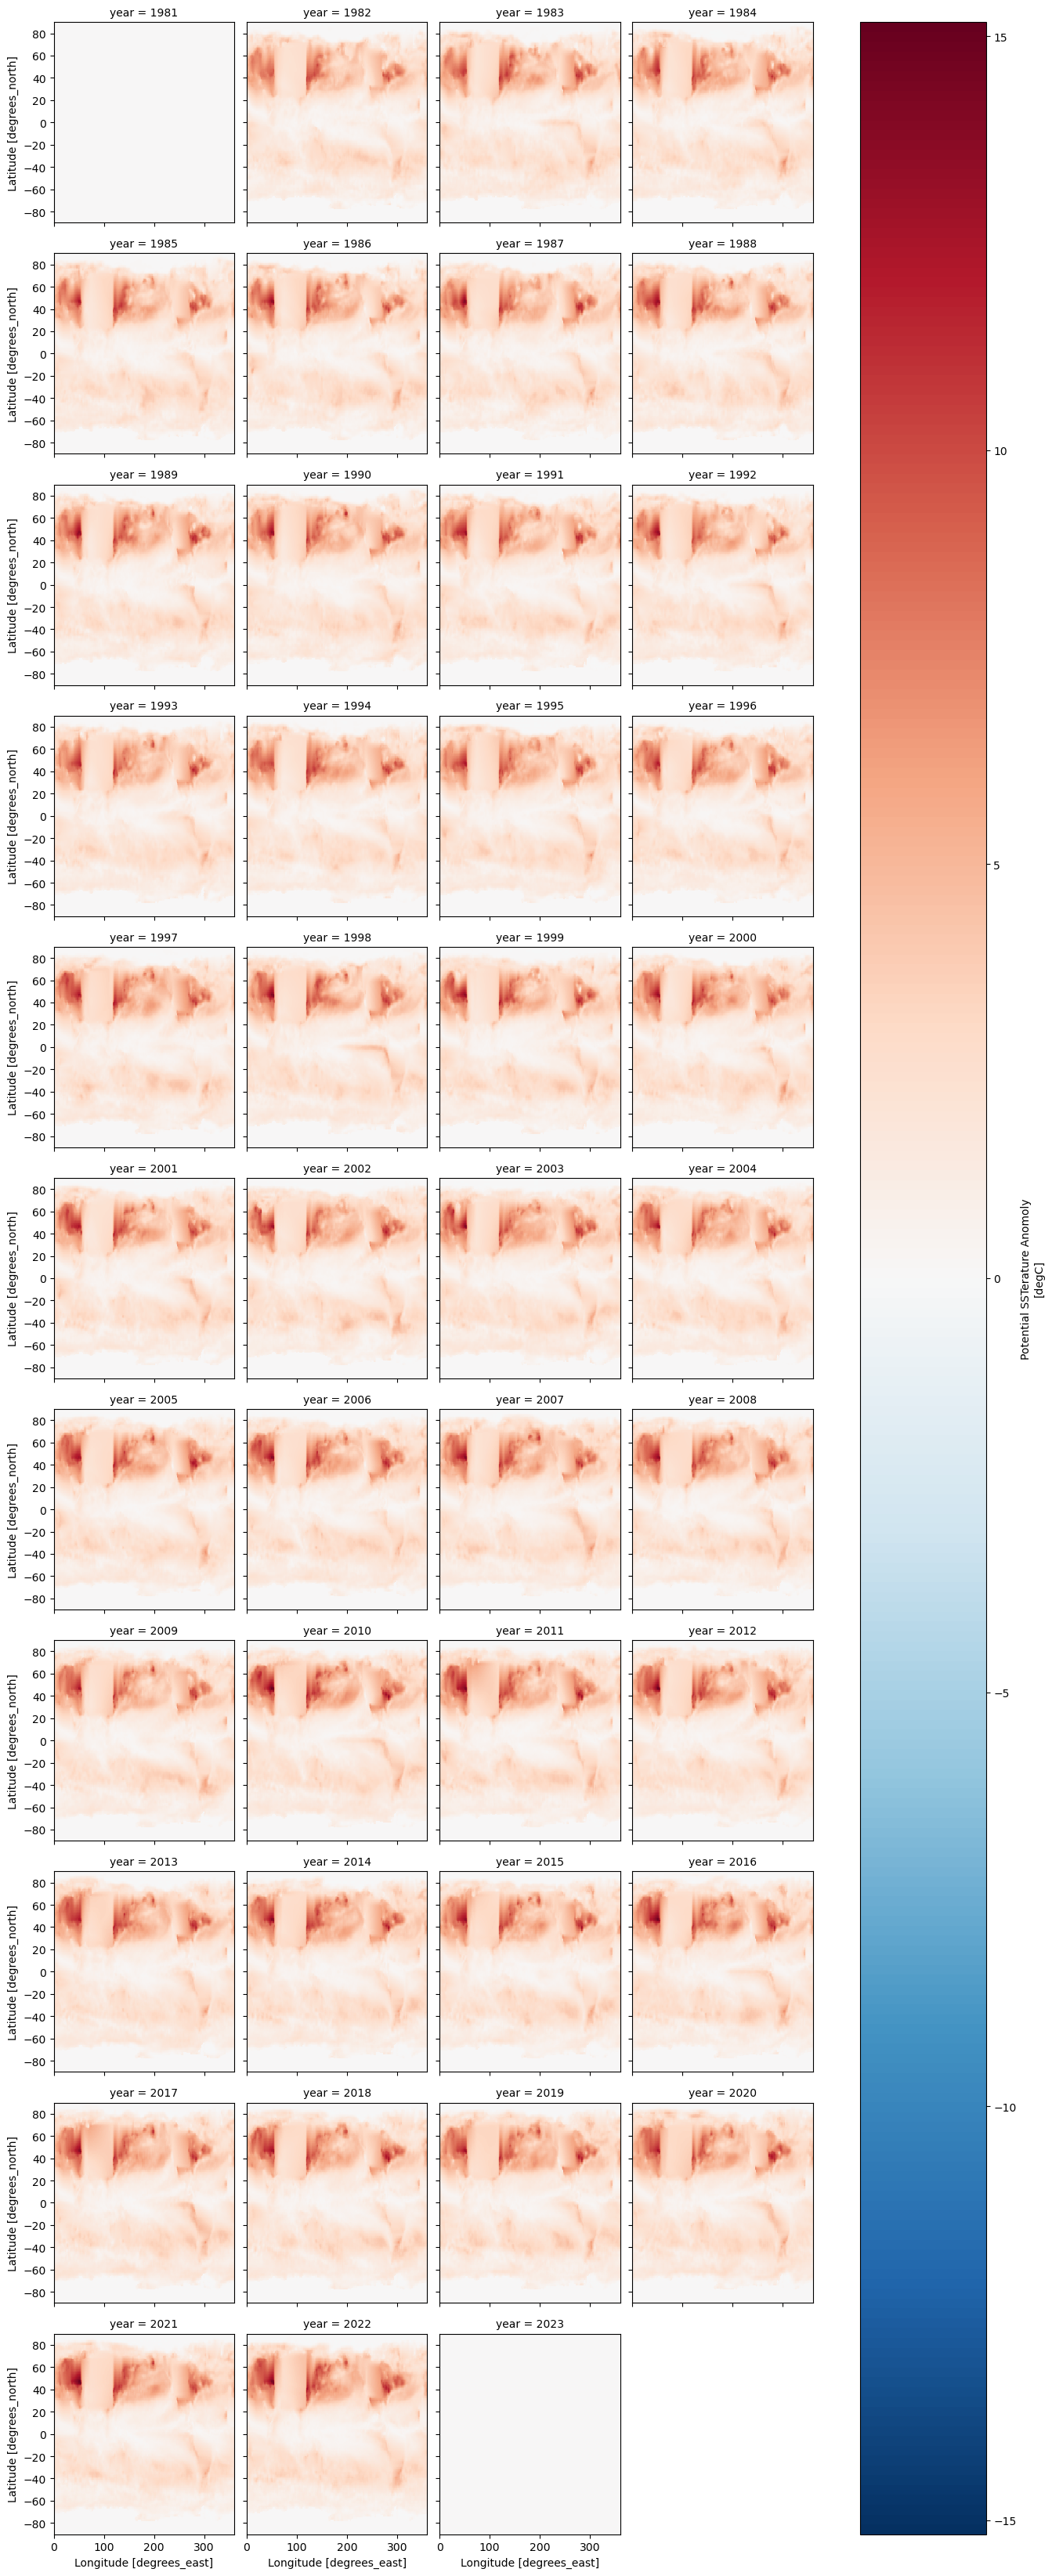

In [ ]:
quantile_upp_ann.plot(col='year', col_wrap=4)

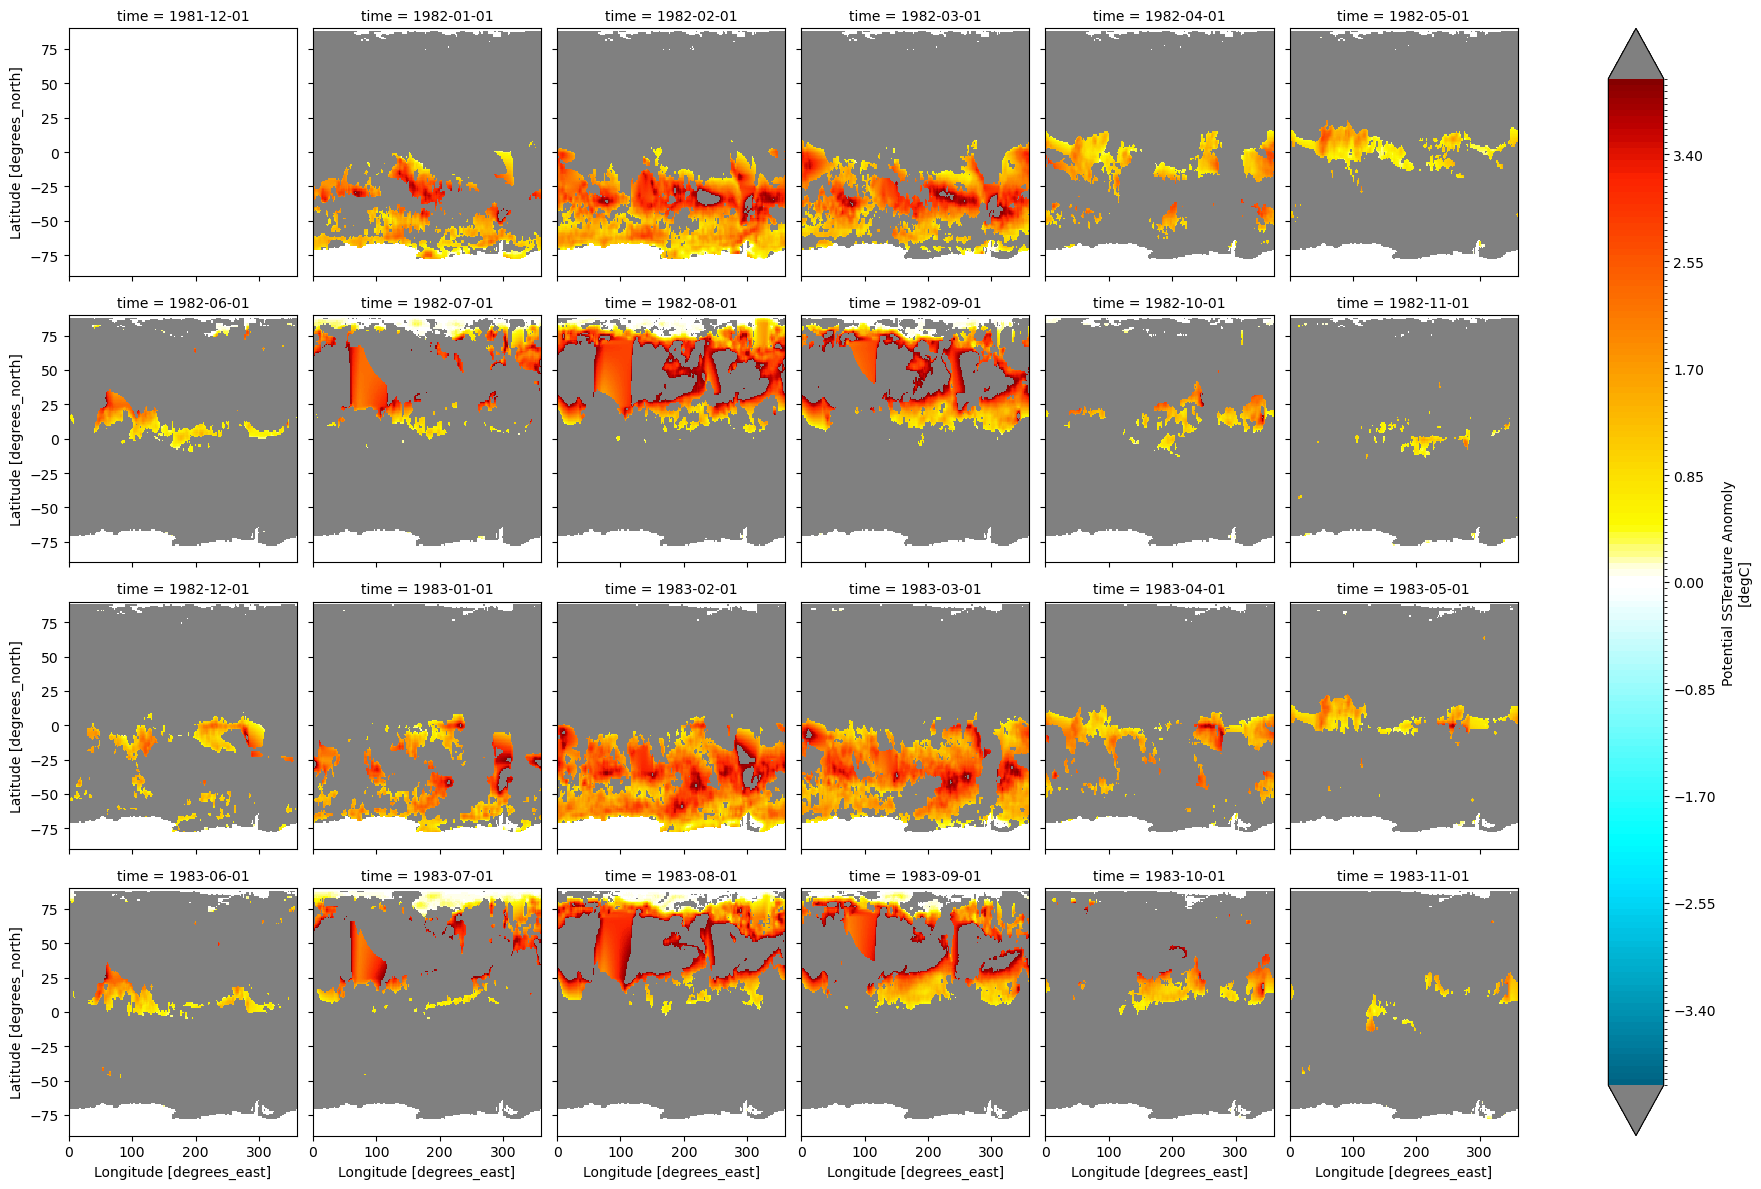

In [ ]:
# Marine Heatwaves at Timesteps
ds_obs.isel(time=slice(0,24)).MHW_annual.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

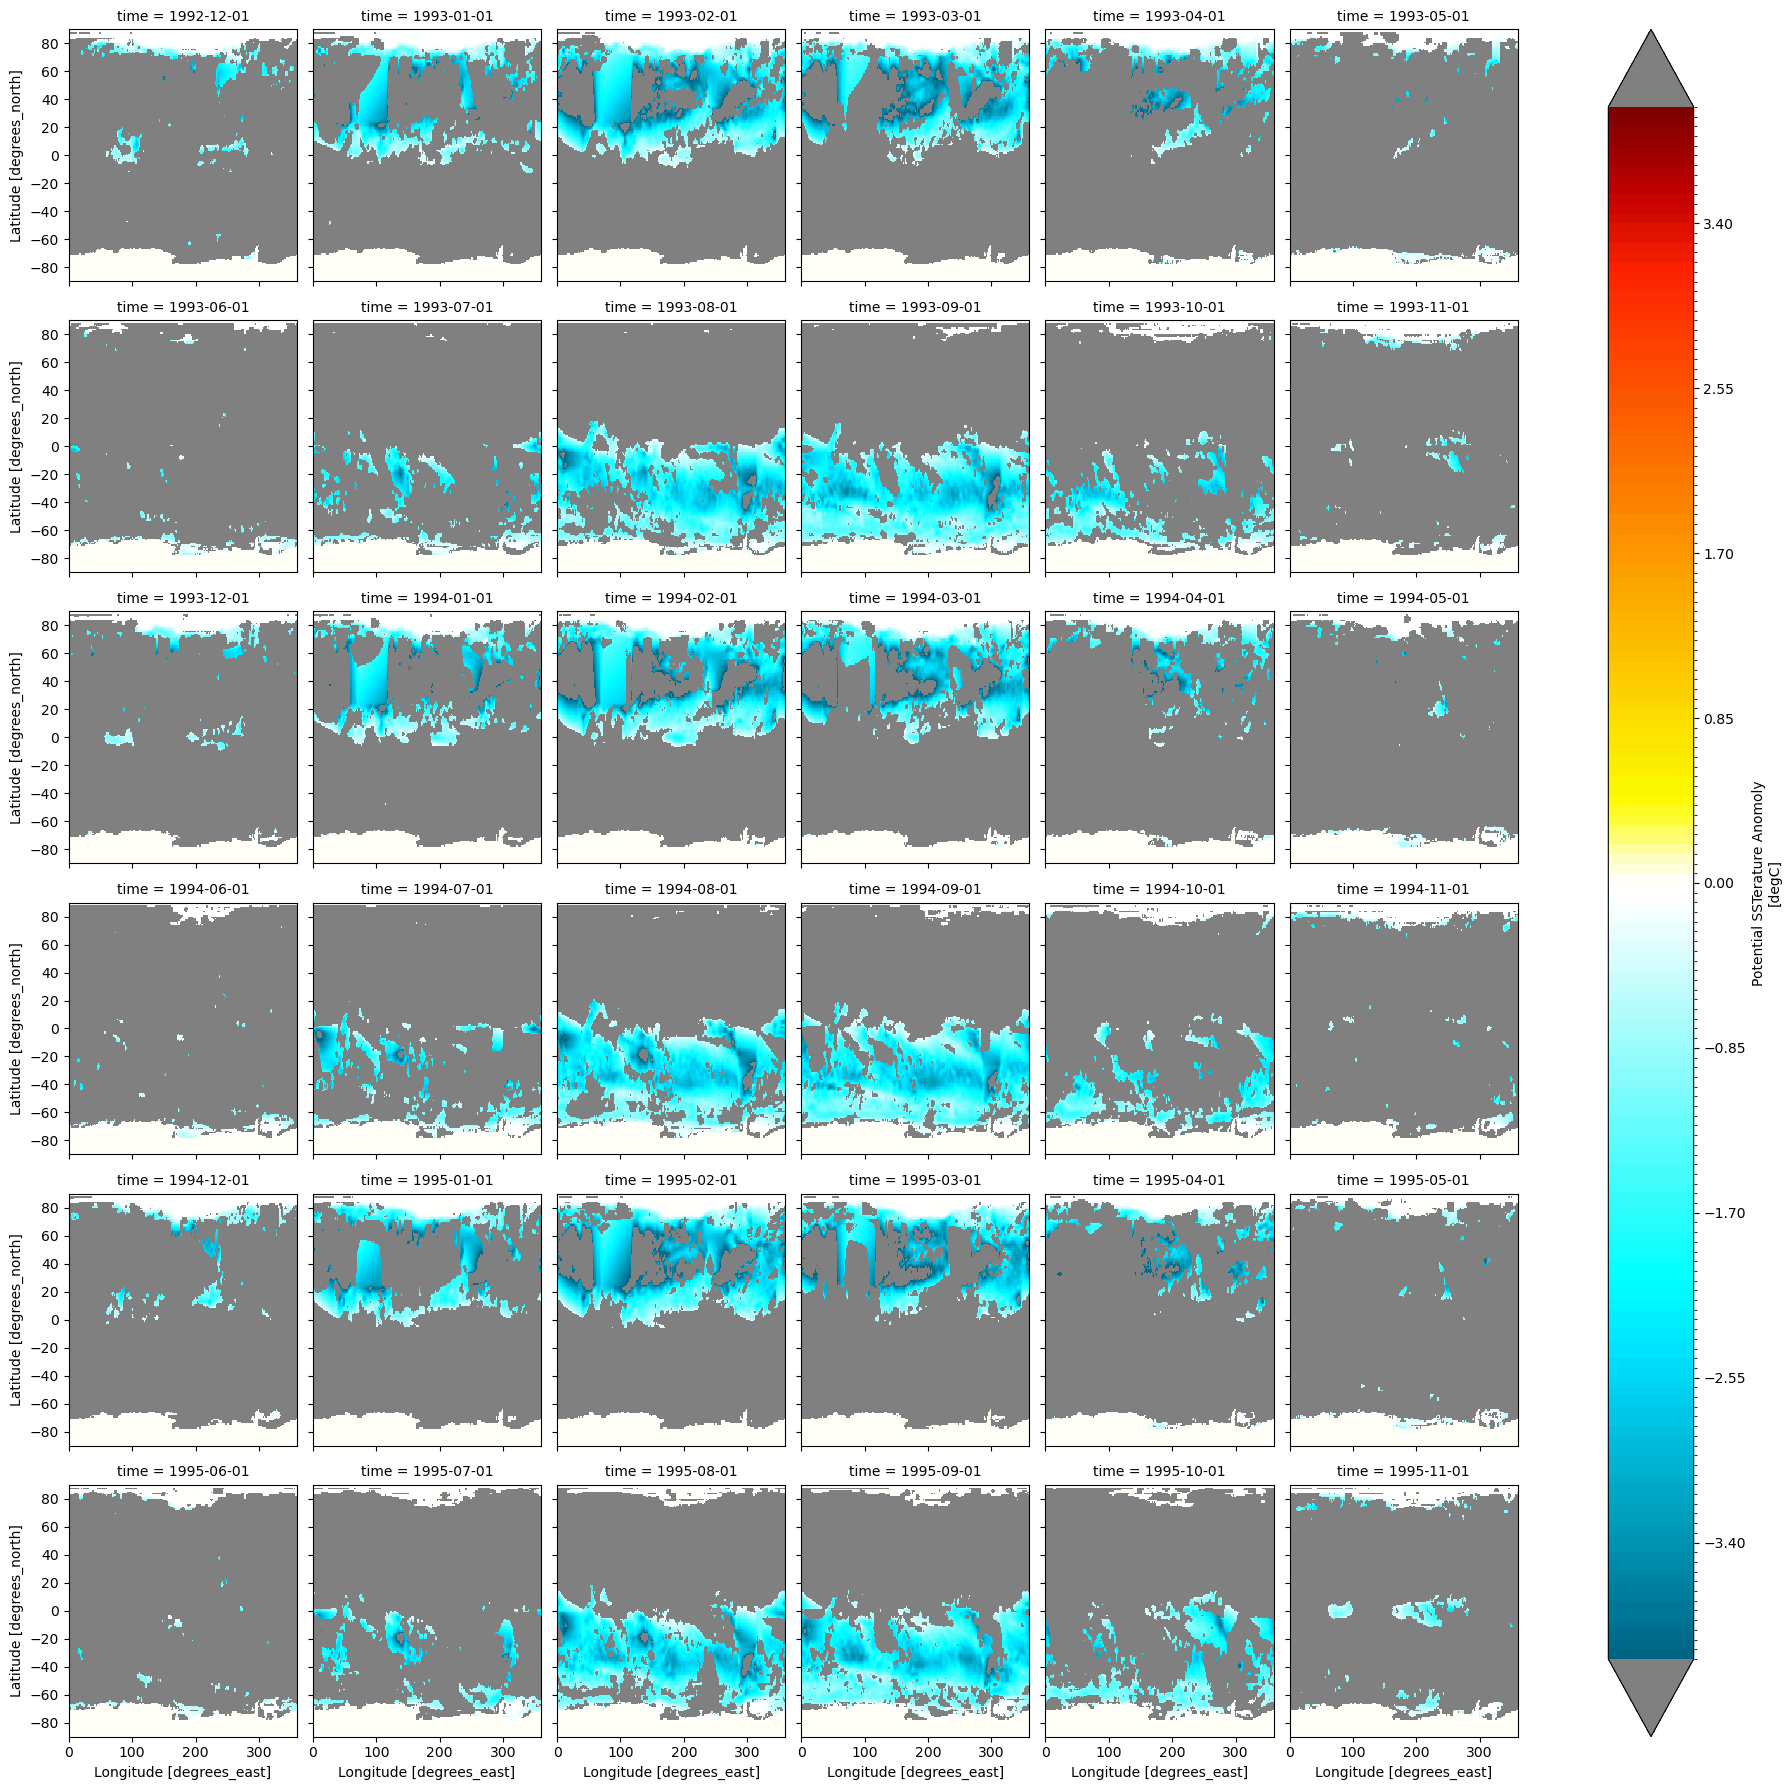

In [ ]:
# Marine Coldwaves at Timesteps

ds_obs.isel(time=slice(11*12,14*12)).MCW_annual.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

In [ ]:
# Compute Intensity and Merge MHW and MCW together

ds_intensity_ann = xr.merge([ds_obs.MHW_annual.where(ds_obs.MHW_annual>-999, drop=False).groupby('time.year').mean('time').rename('MHW_INTENSITY_year'),ds_obs.MCW_annual.where(ds_obs.MCW_annual>-999, drop=False).groupby('time.year').mean('time').rename('MCW_INTENSITY_year')])

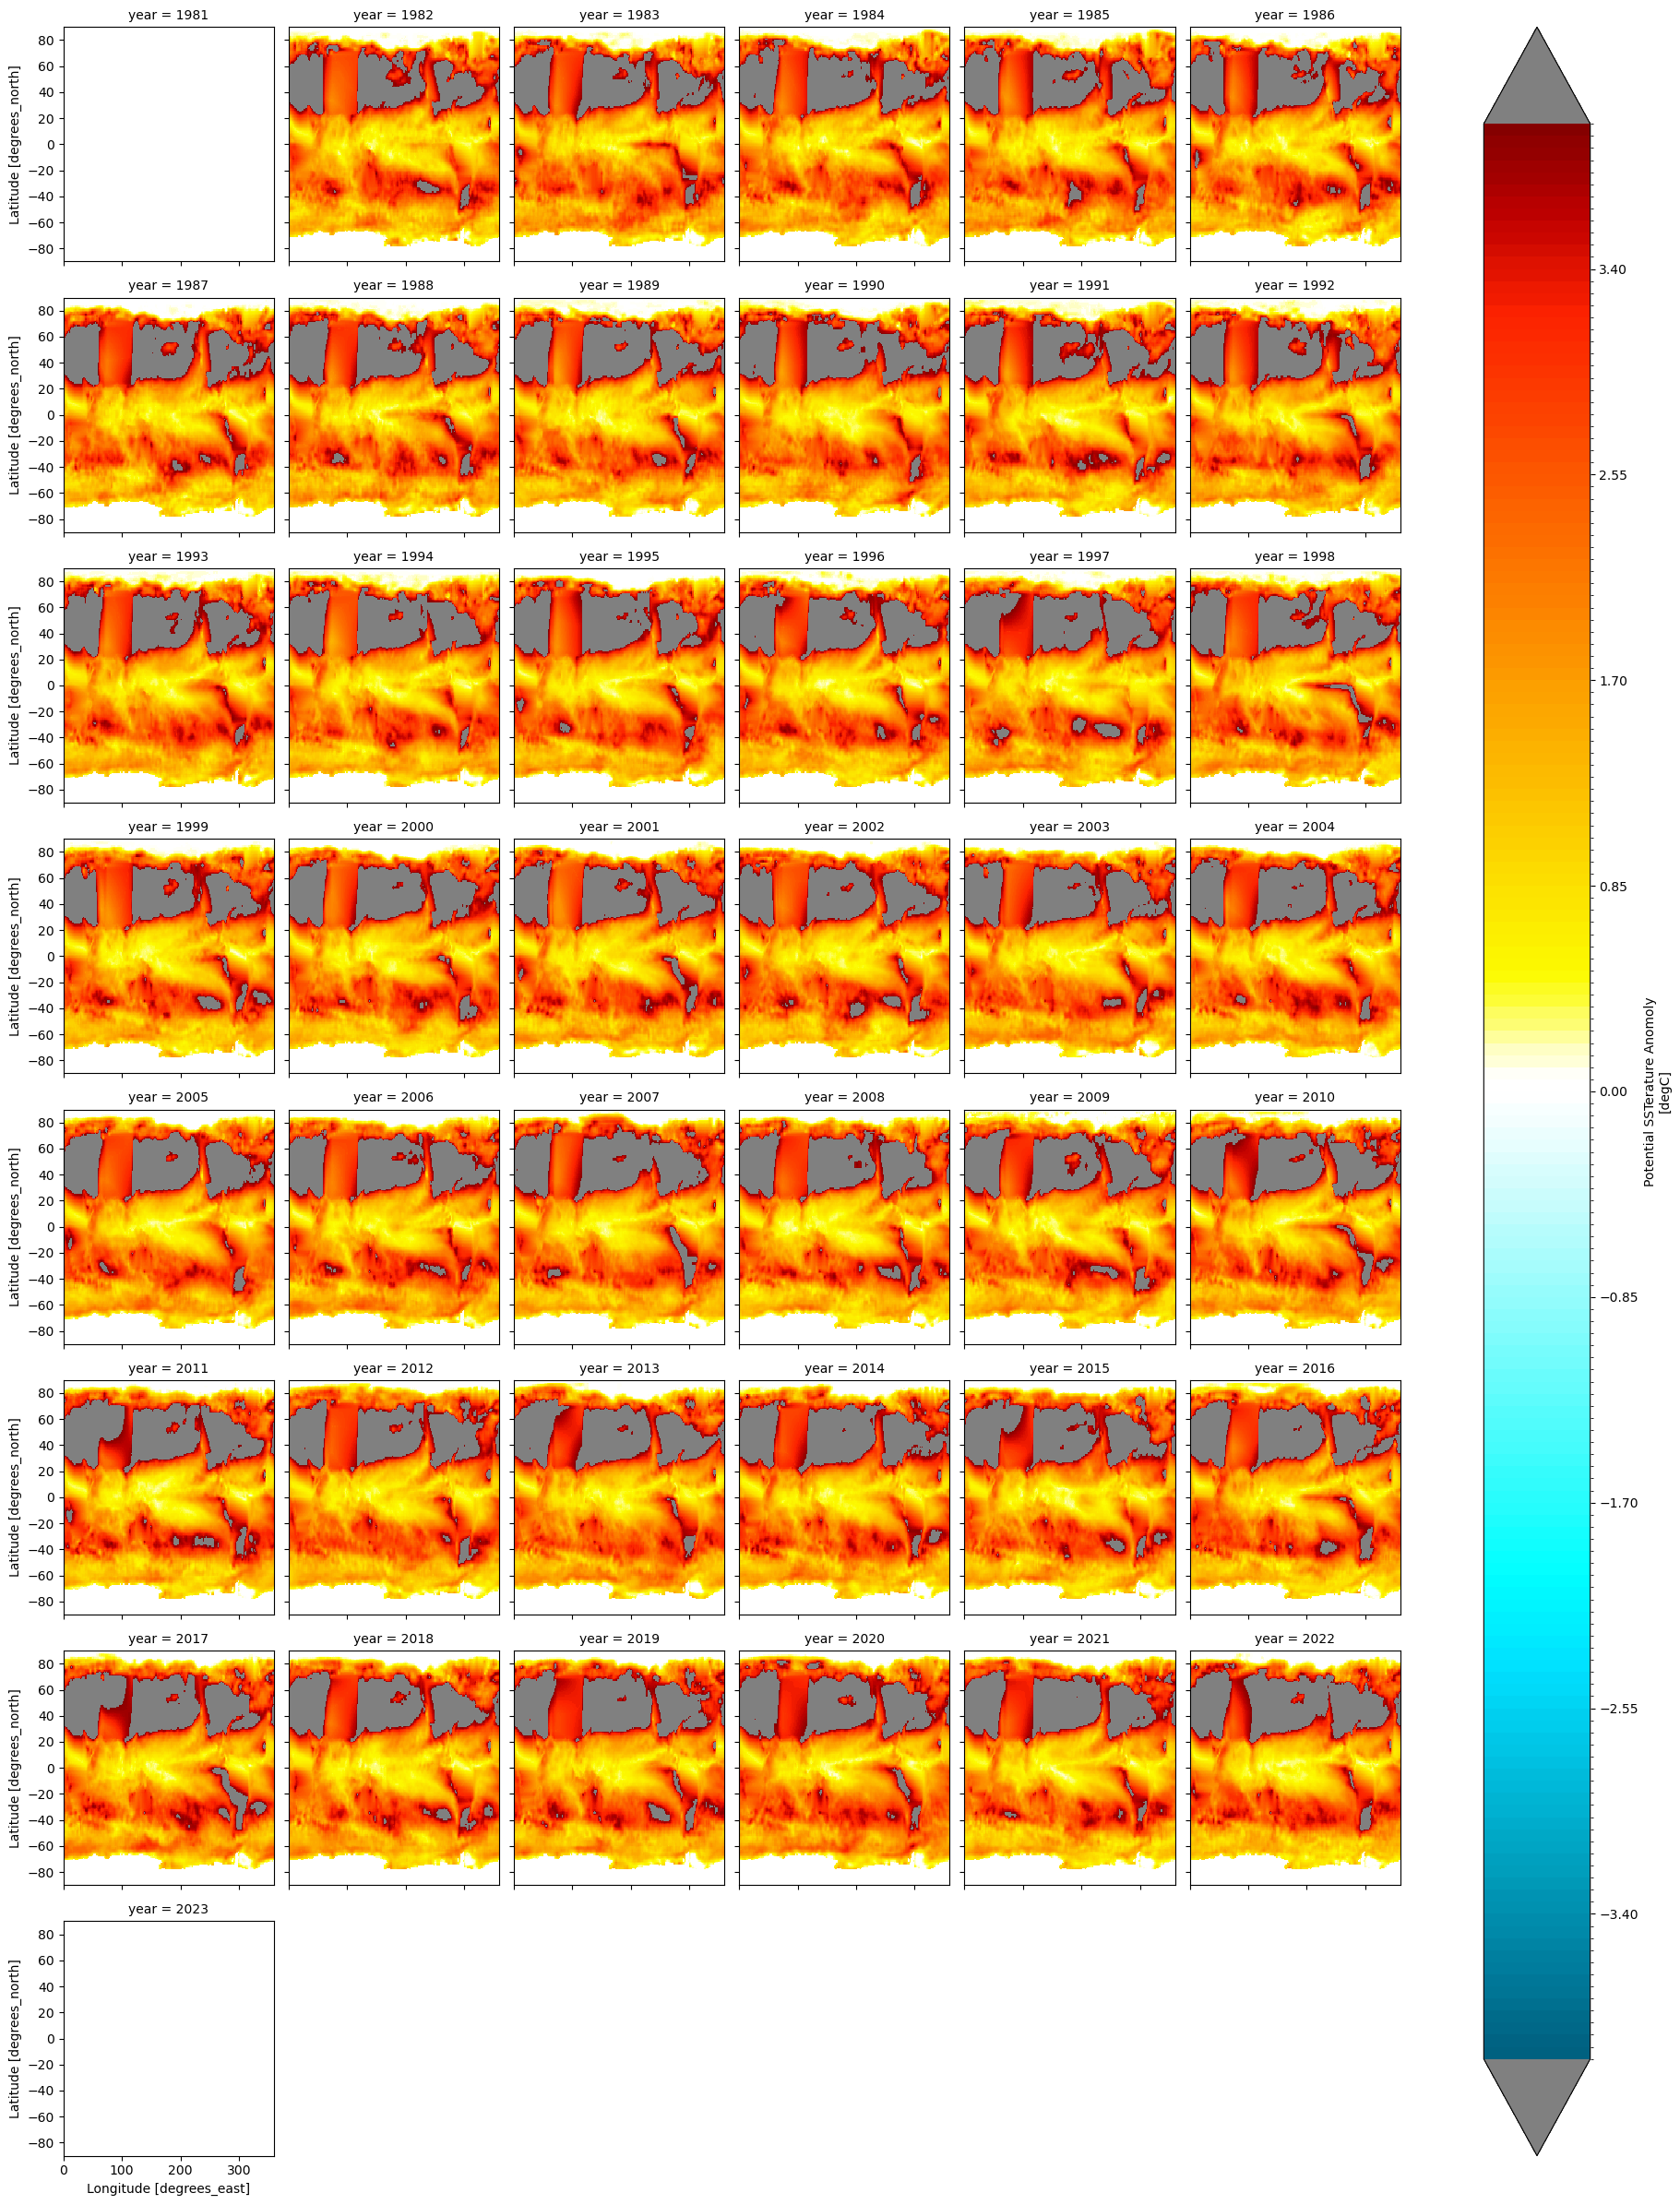

In [ ]:
# Intensity of Marine Heatwaves

ds_intensity_ann['MHW_INTENSITY_year'].plot(col='year',col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

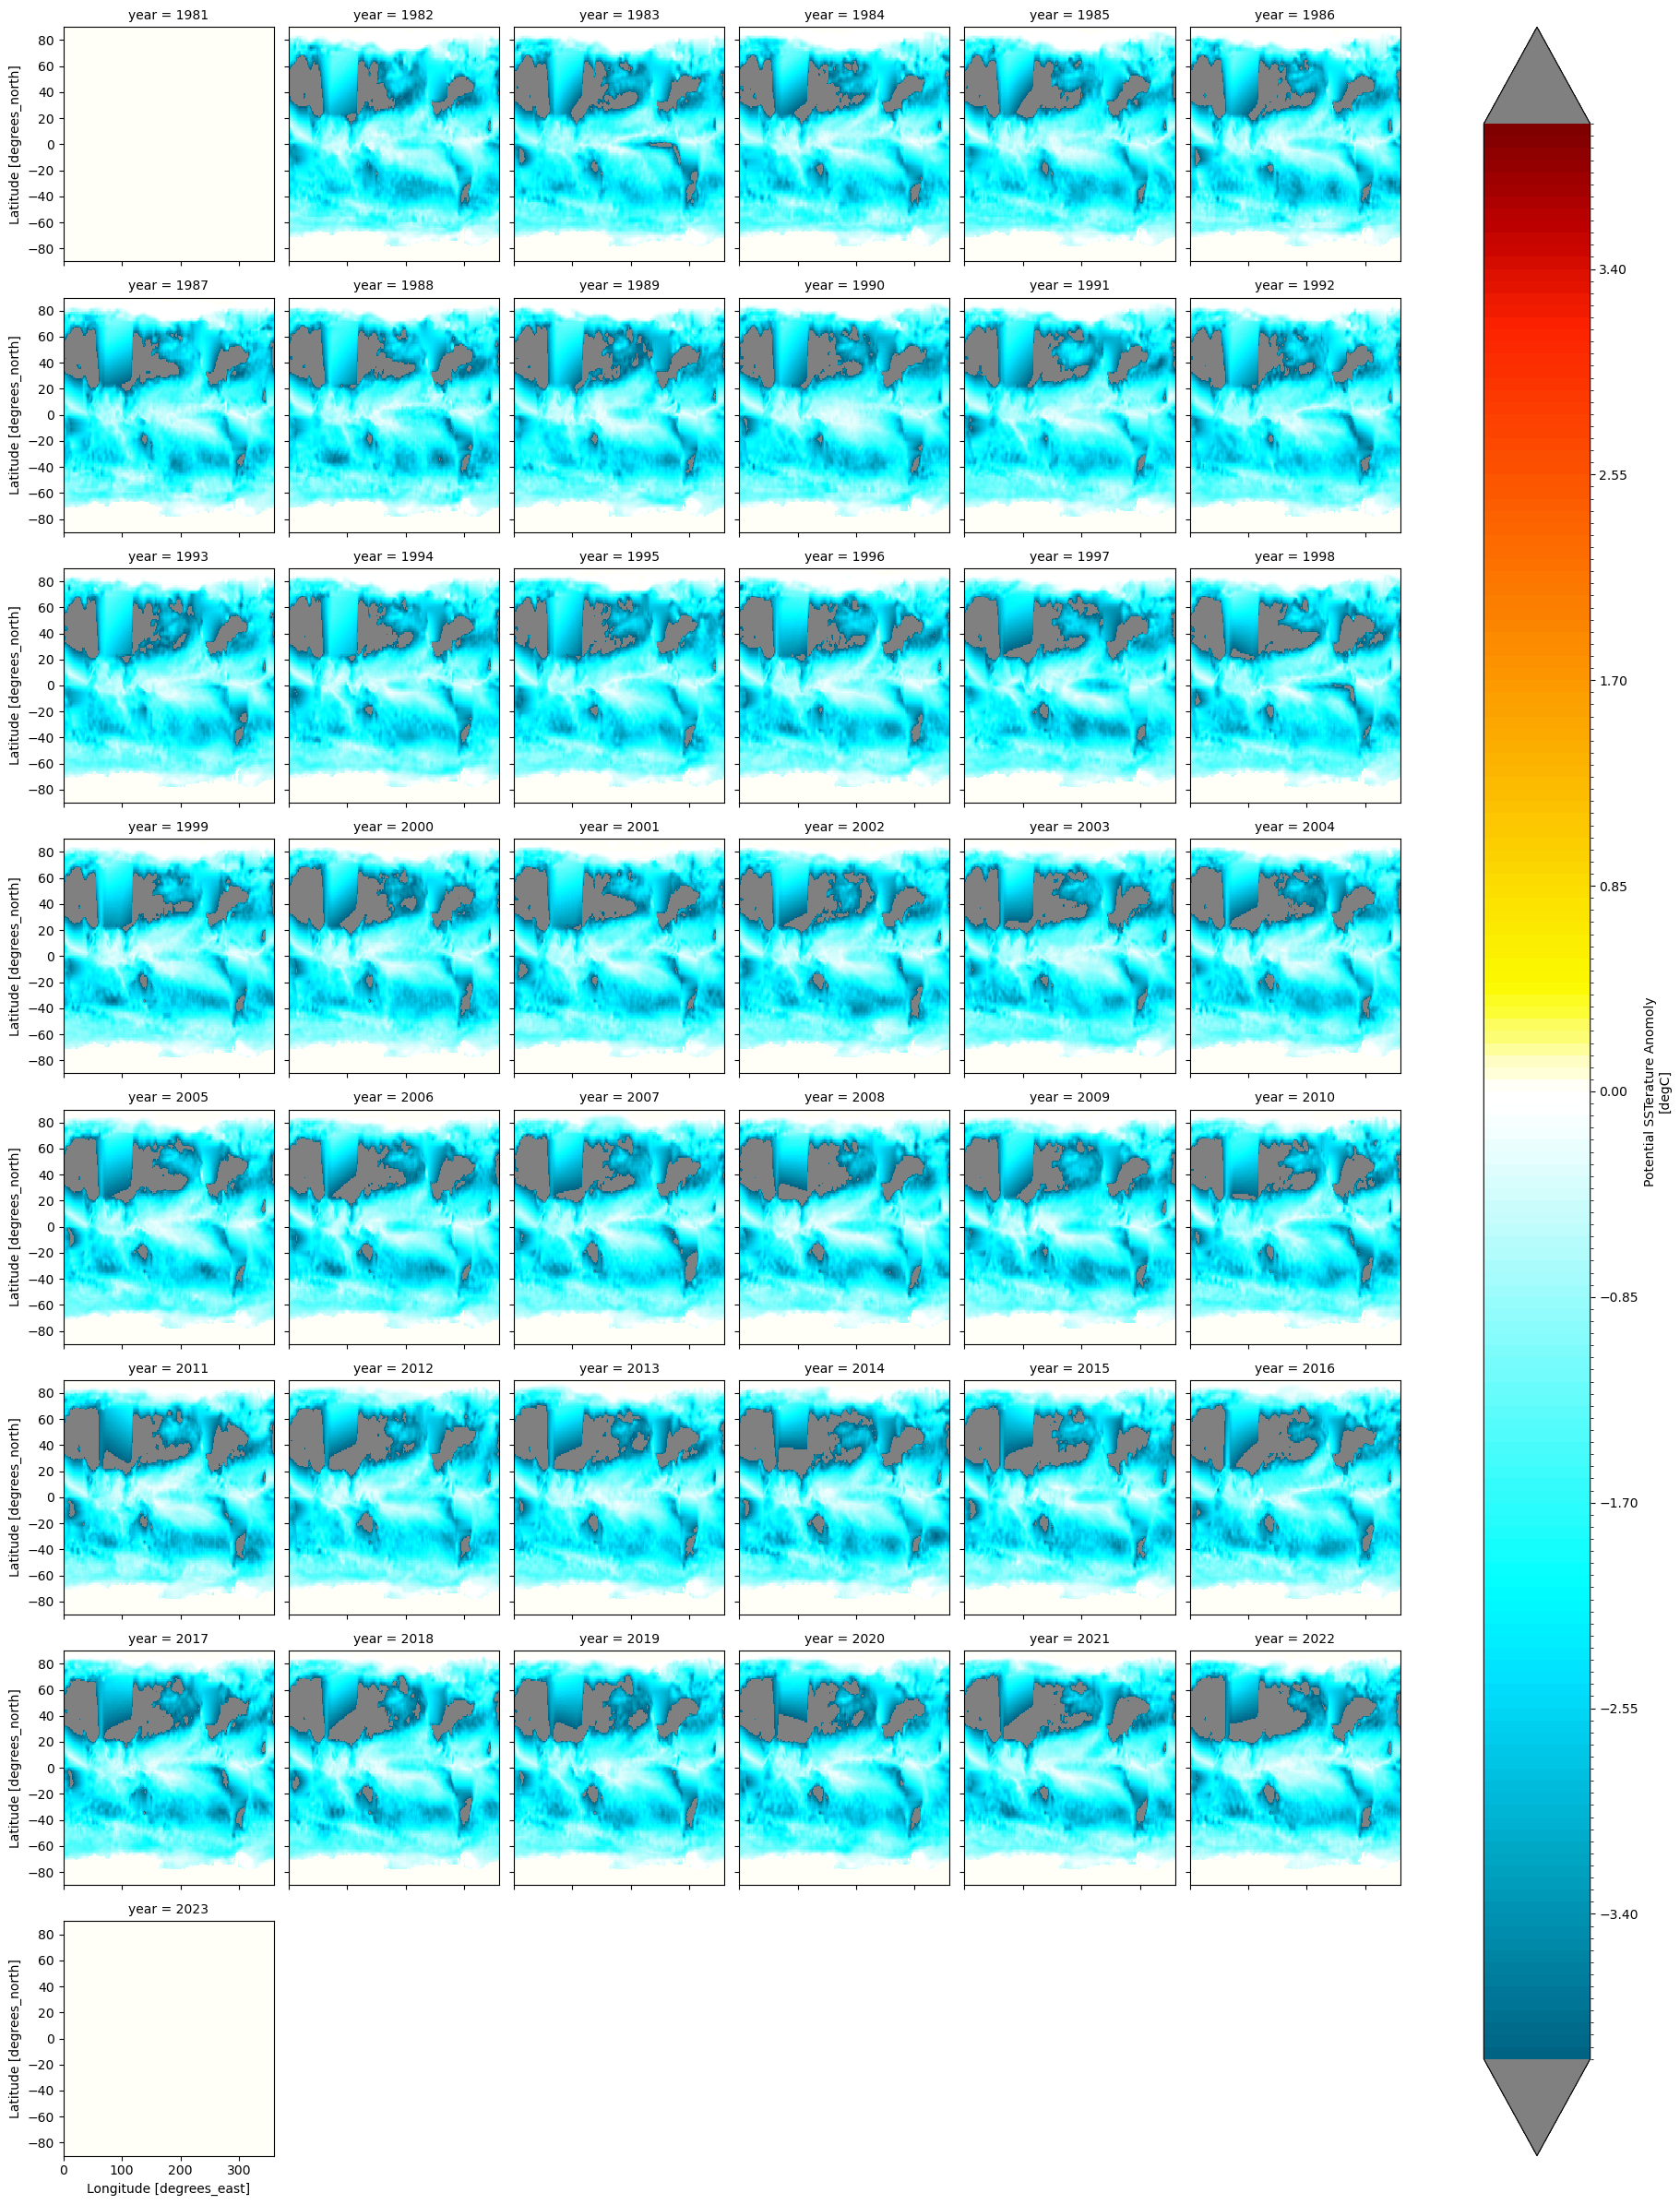

In [ ]:
# Intensity of Marine Coldwaves

ds_intensity_ann['MCW_INTENSITY_year'].plot(col='year',col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

In [ ]:
ds_intensity_ann

<xarray.Dataset> Size: 22MB
Dimensions:             (lat: 180, lon: 360, year: 43)
Coordinates:
  * lat                 (lat) float32 720B 89.5 88.5 87.5 ... -87.5 -88.5 -89.5
  * lon                 (lon) float32 1kB 0.5 1.5 2.5 3.5 ... 357.5 358.5 359.5
  * year                (year) int64 344B 1981 1982 1983 1984 ... 2021 2022 2023
Data variables:
    MHW_INTENSITY_year  (year, lat, lon) float32 11MB 0.0 0.0 0.0 ... 0.0 0.0
    MCW_INTENSITY_year  (year, lat, lon) float32 11MB 0.0 0.0 0.0 ... 0.0 0.0
Attributes: (12/14)
    long_name:             Potential SSTerature Anomoly
    unpacked_valid_range:  [-5. 40.]
    actual_range:          [-1.7999996 35.56862  ]
    units:                 degC
    precision:             2
    var_desc:              Sea Surface Temperature
    ...                    ...
    statistic:             Mean
    parent_stat:           Weekly Mean
    standard_name:         sea_surface_temperature
    cell_methods:          time: mean (monthly from weekly values interpolate...
    valid_range:           [-500 4000]
    quantile:              0.9

In [ ]:
ds_intensity_mon

<xarray.Dataset> Size: 6MB
Dimensions:              (lat: 180, lon: 360, month: 12)
Coordinates:
  * lat                  (lat) float32 720B 89.5 88.5 87.5 ... -87.5 -88.5 -89.5
  * lon                  (lon) float32 1kB 0.5 1.5 2.5 3.5 ... 357.5 358.5 359.5
  * month                (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    MHW_INTENSITY_month  (month, lat, lon) float32 3MB 0.0 0.0 0.0 ... 0.0 0.0
    MCW_INTENSITY_month  (month, lat, lon) float32 3MB 0.0 0.0 0.0 ... 0.0 0.0
Attributes: (12/14)
    long_name:             Potential SSTerature Anomoly
    unpacked_valid_range:  [-5. 40.]
    actual_range:          [-1.7999996 35.56862  ]
    units:                 degC
    precision:             2
    var_desc:              Sea Surface Temperature
    ...                    ...
    statistic:             Mean
    parent_stat:           Weekly Mean
    standard_name:         sea_surface_temperature
    cell_methods:          time: mean (monthly from weekly values interpolate...
    valid_range:           [-500 4000]
    quantile:              0.9

In [ ]:
ds_intensity = xr.merge([ds_intensity_ann, ds_intensity_mon])

## Dask Maxxing

In [ ]:
# # Frequency of MHW
# ### SINCE THIS IS QUANTILE PER LOCATION IT DOESN'T MAKE SENSE, will always be 2

# def freq_ufunc(arr):
#     not_nan = arr[~np.isnan(arr)]
#     if len(not_nan)!=0:
#         not_nan = not_nan[not_nan!=-9999]
#         freq = len(not_nan)/len(arr)
#     else:
#         freq = np.nan
#     return freq

# def frequency_per_mon(groups):
#     res_list = []
#     var_list = ['MHW', 'MCW']
#     for var in var_list:
#         result = xr.apply_ufunc(freq_ufunc,
#                                 groups[var],
#                                 input_core_dims=[['time']],
#                                 output_core_dims=[[]],
#                                 vectorize=True,
#                                 dask="parallelized",
#                                 on_missing_core_dim='copy'
#                                 )
#         result = result.rename(var+'_FREQ')
#         result.attrs = {'long_name': 'Frequency of Marine Heatwave/Coldwave Events, normalized by time', 'units': ''}
#         res_list.append(result)
#     out = xr.merge(res_list)
#     return out

# # Apply the custom function using groupby and map
# ds_frequency = ds_obs.groupby("time.month").map(frequency_per_mon)#.plot(levels=np.arange(0, 1.1, .1), col='month', col_wrap=3)

In [ ]:
# ### Intensity of MHW's

# def intense_ufunc(ex_arr):#, t_arr):
#     not_nan = ex_arr[~np.isnan(ex_arr)]
#     if len(not_nan)!=0:
#         # not_nan = not_nan[not_nan>-999]
#         intense = (np.mean(ex_arr))# - np.mean(t_arr)) / np.std(t_arr)  #zscore of average mhw/mcw
#     else:
#         intense = np.nan
#     return intense

# def intensity_per_mon(group):
#     res_list = []
#     var_list = ['MHW', 'MCW']
#     for var in var_list:
#         print(group[var].where(group[var]>-999, drop=True))
#         result = xr.apply_ufunc(intense_ufunc,
#                                 group[var].where(group[var]>-999, drop=False),
#                                 # groups['SST'],
#                                 input_core_dims=[['time']],#,['time']],
#                                 output_core_dims=[[]],
#                                 vectorize=True,
#                                 # dask="parallelized",
#                                 on_missing_core_dim='copy'
#                                 )
#         result = result.rename(var+'_INTE')
#         result.attrs = {'long_name': 'Intensity of Marine Heatwave Events, normalized by time', 'units': ''}
#         res_list.append(result)
#     out = xr.merge(res_list)
#     return out

# # Apply the custom function using groupby and map
# ds_intensity = ds_obs.groupby("time.month").map(intensity_per_mon)

# ds_intensity.MCW_INTE.plot(levels=np.arange(-999, 1.1, .1), col='month', col_wrap=3)